# Supplementary Fig. 4b: statistics of the firing rates of the sorted single-units, by spike sorter and layer

**author**: laquitainesteeve@gmail.com

**purpose**: reproduce panel b of Supplementary Fig. 4: boxplots of the log10 firing rates of the sorted single-units of the Marques-Smith recording (M, grey), the biophysical models of the spontaneous (NS, red) and evoked (E, orange) regimes and the synthetic model (S, blue; layer 5 only) for each layer and each spike sorter (columns). Notches are 95% confidence intervals. Statistical significance of the difference between each model and Marques-Smith is reported with ns, *, **, *** (p >= 0.05, p < 0.05, p < 0.01, p < 0.001, two-sided Mann-Whitney U test). Source data and svg are saved in figures/8_source_data/supp_fig4b/.

**method (as in supp_fig4a.ipynb and fig4b.ipynb)**: sortings of the first 10 minutes of each recording; units in cortex; single-units only (Kilosort's 'good' label), except for Kilosort which does not label units; the stored firing rates of the sorting of the evoked regime by Kilosort3 are recomputed (see `fix_firing_rates` in `src/nodes/validation/firing_rate.py`).

In [1]:
%load_ext autoreload
%autoreload 2
from matplotlib import pyplot as plt
import numpy as np
import os
import warnings
import pandas as pd
import seaborn as sns
import copy
import spikeinterface as si

warnings.simplefilter(action='ignore', category=FutureWarning)
warnings.filterwarnings("ignore")

# SET PROJECT PATH

PROJ_PATH = "/home/steeve/steeve/epfl/code/spikebias"
os.chdir(PROJ_PATH)
from src.nodes.utils import get_config, savefig
from src.nodes.validation import firing_rate as fr
from src.nodes.validation.npx_probe import firing_rate as fr_npx

# SETUP EXPERIMENTS

# sorting paths (10 minutes): dataset/01_intermediate/sorting/<experiment>/<sorting folder>
SORTING_ROOT = "dataset/01_intermediate/sorting"
EXPERIMENT_FOLDERS = {"M": "marques", "NS": "npx_spont", "E": "npx_evoked_40khz", "S": "buccino"}
SORTERS = {                    # title: (sorting folder, only single units?)
    "Kilosort4": ("SortingKS4_10m", True),
    "Kilosort3": ("SortingKS3_10m", True),
    "Kilosort2.5": ("SortingKS2_5_10m", True),
    "Kilosort2": ("SortingKS2_10m", True),
    "Kilosort": ("SortingKS_10m", False),     # Kilosort does not classify single and multi-units: all units are reported
}

# Kilosort4: the sortings of Fig. 4 (M: first 10 minutes of the sorting of the whole recording; NS: Tesla V100 sorting); other sorters: sortings of the first 10 minutes of each recording
PATH_OVERRIDES = {"Kilosort4": {"M": "marques/SortingKS4_10m_rtx5090", "NS": "npx_spont_v100/SortingKS4_10m", "E": "npx_evoked_40khz/SortingKS4_10m"}}

# PARAMETERS
layers = ["L1", "L2/3", "L4", "L5", "L6"]

# SETUP PLOT 

# set lognormal plot parameters
log_x_min = -3.0
log_x_max = 3.0
nbins = 30

# IF you don't want to use the feature, set the value to 1E100
# t_dec = 3600 # seconds until experimenter decides a cell is silent
t_dec = 1^100 # seconds until experimenter decides a cell is silent

cl = dict()
cl["COLOR_NV"] = [0.6, 0.6, 0.6]
cl["COLOR_NS"] = [0.9, 0.14, 0.15]
cl["COLOR_NB"] = [0.22, 0.5, 0.72] # blue
cl["COLOR_NE"] = [1, 0.49, 0] # orange
cl["COLOR_HV"] = "k" # black
cl["COLOR_HS"] = np.array([26, 152, 80]) / 255 # green

# axes
plt.rcParams["font.family"] = "DejaVu Sans"   # the paper's figure was drawn without Arial (matplotlib default font)
plt.rcParams["font.size"] = 6  # 5-7 with Nature neuroscience as reference
plt.rcParams["lines.linewidth"] = 0.5 # typically between 0.5 and 1
plt.rcParams["axes.linewidth"] = 0.5 #1
plt.rcParams["axes.spines.top"] = False
plt.rcParams["xtick.major.width"] = 0.5 #0.8 #* 1.3
plt.rcParams["xtick.minor.width"] = 0.5 #0.8 #* 1.3
plt.rcParams["ytick.major.width"] = 0.5 #0.8 #* 1.3
plt.rcParams["ytick.minor.width"] = 0.5 #0.8 #* 1.3
plt.rcParams["xtick.major.size"] = 3.5 * 1.1
plt.rcParams["xtick.minor.size"] = 2 * 1.1
plt.rcParams["ytick.major.size"] = 3.5 * 1.1
plt.rcParams["ytick.minor.size"] = 2 * 1.1

# legend
legend_cfg = {"frameon": False, "handletextpad": 0.5}
tight_layout_cfg = {"pad": 0.001}
LG_FRAMEON = False              # no legend frame

savefig_cfg = {"transparent":True, "dpi": 400}

In [2]:
# Nature figure guidelines for every saved figure: Arial, 5-7 pt, editable text, images of at least 300 dpi, a .pdf next to each .svg
import os, sys
sys.path.insert(0, os.getcwd())     # the repository (the notebook moved there above)
from src.nodes import figure_style
figure_style.apply()

## Get the metadata of the sorted units

In [3]:
%%time

LAYER_NAMES = ["L1", "L2/3", "L4", "L5", "L6"]
DURATION_SEC = 600              # duration of the sortings
df_units = {}       # {sorter title: {experiment: units}}
for title, (folder, single_unit) in SORTERS.items():
    df = {}
    for exp, exp_folder in EXPERIMENT_FOLDERS.items():
        path = f"{SORTING_ROOT}/" + PATH_OVERRIDES.get(title, {}).get(exp, f"{exp_folder}/{folder}")
        d = fr.get_synth_unit_meta(path) if exp == "S" else fr.get_sorted_unit_meta(path)
        d = fr.fix_firing_rates(d, si.load_extractor(path), path, DURATION_SEC)
        if exp != "S":
            d = d[np.isin(d["layer"], LAYER_NAMES)]           # units in cortex
        if single_unit:
            d = d[d["kslabel"] == "good"]
        df[exp] = d
    df_units[title] = df
    print(f"{title:12s} unit counts:", {e: d.shape[0] for e, d in df.items()})

Kilosort4    unit counts: {'M': 106, 'NS': 257, 'E': 273, 'S': 377}
Kilosort3    unit counts: {'M': 111, 'NS': 233, 'E': 333, 'S': 349}


Kilosort2.5  unit counts: {'M': 186, 'NS': 578, 'E': 196, 'S': 413}
Kilosort2    unit counts: {'M': 944, 'NS': 1187, 'E': 205, 'S': 1512}
2026-11-05 14:25:42,898 - root - utils.py - get_kslabel - INFO - No KSLabel property in SortingExtractor


2026-11-05 14:25:42,899 - root - utils.py - get_amplitude - INFO - No Amplitude property in SortingExtractor


2026-11-05 14:25:42,934 - root - utils.py - get_kslabel - INFO - No KSLabel property in SortingExtractor


2026-11-05 14:25:42,934 - root - utils.py - get_amplitude - INFO - No Amplitude property in SortingExtractor


2026-11-05 14:25:42,969 - root - utils.py - get_kslabel - INFO - No KSLabel property in SortingExtractor


2026-11-05 14:25:42,970 - root - utils.py - get_amplitude - INFO - No Amplitude property in SortingExtractor


2026-11-05 14:25:42,996 - root - utils.py - get_kslabel - INFO - No KSLabel property in SortingExtractor


2026-11-05 14:25:42,997 - root - utils.py - get_amplitude - INFO - No Amplitude property in SortingExtractor


Kilosort     unit counts: {'M': 1457, 'NS': 1806, 'E': 2208, 'S': 1254}
CPU times: user 600 ms, sys: 25.9 ms, total: 626 ms
Wall time: 625 ms


## Log10 firing rates and statistics

In [4]:
%%time

import io
from contextlib import redirect_stdout

EXPS = ["M", "NS", "E", "S"]
XADJ = {"Kilosort4": 1, "Kilosort3": 1, "Kilosort2.5": 2, "Kilosort2": 2, "Kilosort": 1}        # position of the significance marks
df_fr, stats = [], []
for title, df in df_units.items():
    fig_tmp, ax_tmp = plt.subplots(1)
    ax_tmp, d = fr_npx.plot_fr_stats_by_layer_vert(ax_tmp, df["M"], df["NS"], df["E"], df["S"], layers, cl)       # log10 firing rate of each unit
    plt.close(fig_tmp)
    df_fr.append(d.assign(sorter=title))

    # Mann-Whitney U test of each experiment vs. Marques-Smith in each layer
    with redirect_stdout(io.StringIO()):
        hashed = fr_npx.get_stats(d, "firing rate", layers, EXPS)
    for layer in layers:
        for exp in EXPS[1:]:
            h = hashed[layer][exp]
            stats.append(dict(sorter=title, layer=layer, comparison=f"M vs. {exp}", n_M=int(((d.layer == layer) & (d.experiment == "M")).sum()), n_other=int(((d.layer == layer) & (d.experiment == exp)).sum()),
                              U=h.get("z", np.nan), p=h.get("p", np.nan), significance=h["symbol"]))
df_fr, stats = pd.concat(df_fr, ignore_index=True), pd.DataFrame(stats)

# effect sizes: medians (spikes/s in b, variance in c), difference of the medians (simulation - M) and its 95% bootstrap confidence interval (10,000 resamples, seed 0)
N_BOOT, TO_RATE = 10_000, lambda v: 10 ** v
rng = np.random.default_rng(0)
effect = []
for _, r in stats.iterrows():
    pick = lambda e: df_fr[(df_fr["sorter"] == r["sorter"]) & (df_fr["layer"] == r["layer"]) & (df_fr["experiment"] == e)]["firing rate"].dropna().values
    m, x = pick("M"), pick(r["comparison"].split()[-1].rstrip("."))
    if len(m) == 0 or len(x) == 0:
        effect.append(dict(median_M=np.nan, median_other=np.nan, difference_of_medians=np.nan, ci95_low=np.nan, ci95_high=np.nan))
        continue
    m, x = TO_RATE(m), TO_RATE(x)
    boot = [np.median(rng.choice(x, len(x))) - np.median(rng.choice(m, len(m))) for _ in range(N_BOOT)]
    effect.append(dict(median_M=np.median(m), median_other=np.median(x), difference_of_medians=np.median(x) - np.median(m), ci95_low=np.percentile(boot, 2.5), ci95_high=np.percentile(boot, 97.5)))
stats = pd.concat([stats.iloc[:, :5], pd.DataFrame(effect), stats.iloc[:, 5:]], axis=1)
display(stats[stats.significance != ""].pivot_table(index=["sorter", "layer"], columns="comparison", values="significance", aggfunc="first").reindex(list(SORTERS), level=0))

comparison        M vs. E M vs. NS M vs. S
sorter      layer                         
Kilosort4   L2/3       ns       ns     NaN
            L4         ns       ns     NaN
            L5         ns       ns     ***
            L6          *        *     NaN
Kilosort3   L2/3        *       ns     NaN
            L4         ns       ns     NaN
            L5         ns       ns     ***
            L6         ns       ns     NaN
Kilosort2.5 L4         ns       ns     NaN
            L5        ***       **     ***
            L6        ***       ns     NaN
Kilosort2   L4         ns       ns     NaN
            L5        ***       **      ns
            L6        ***      ***     NaN
Kilosort    L4         ns       ns     NaN
            L5        ***      ***     ***
            L6        ***      ***     NaN

CPU times: user 10.5 s, sys: 4.05 ms, total: 10.5 s
Wall time: 10.5 s


## Plot, same as the paper's panel b

In [5]:
BOXPLOT_PMS = {
    "notch": True,  # notches are 95% CI
    "gap": 0.2,
    "width": 0.7,
    "linewidth": 0.5,
    "flierprops": {"marker": "o", "markerfacecolor": "w", "markersize": 1.5, "markeredgewidth": 0.5},
    "boxprops": {"linewidth": 0.5},
}
XTICKS = {"Kilosort4": ([-1, 0, 1, 2], (-1, 2.2)), "Kilosort3": ([-1, 0, 1], (-1, 2.2)), "Kilosort2.5": ([-3, -2, -1, 0, 1, 2], (-3, 3)),
          "Kilosort2": ([-3, -2, -1, 0, 1, 2, 3], (-3, 3)), "Kilosort": ([-3, -2, -1, 0, 1, 2, 3], (-3, 4))}


XTICK_LABELS_EVERY_OTHER = ["Kilosort2.5", "Kilosort2", "Kilosort"]       # tick labels are only written every 2 units (as in the paper)
AX_W, AX_H, AX_PITCH = 0.48, 2.28, 0.6          # inches: axes width, axes height and distance between the axes of two sorters


def plot_source_data(df_fr: pd.DataFrame):
    """Boxplots of the log10 firing rates of each experiment in each layer for each sorter, with the significance of the difference from Marques-Smith"""

    from src.nodes.validation import supp_fig4_layout as lay

    fig = lay.new_figure(lay.B_CANVAS)
    axes = lay.axes_bc(fig, lay.B_LEFT, lay.B_TOP, lay.B_W, lay.B_H)
    for c, (ax, title) in enumerate(zip(axes, SORTERS)):
        d = df_fr[df_fr["sorter"] == title]
        sns.boxplot(ax=ax, data=d, x="firing rate", y="layer", hue="experiment", hue_order=EXPS, palette=[cl["COLOR_NV"], cl["COLOR_NS"], cl["COLOR_NE"], cl["COLOR_NB"]], order=layers, **BOXPLOT_PMS, vert=False)
        ax.spines[["top", "right"]].set_visible(False)
        ax.legend("", frameon=False)
        ax.spines["bottom"].set_position(("axes", -0.05))
        ax.yaxis.set_ticks_position("left")
        ax.spines["left"].set_position(("axes", -0.05))
        ax.set_xlabel("")
        ax.set_ylabel("Layer" if c == 0 else "")
        if c > 0:
            ax.set_yticklabels([])
        ax = fr_npx.set_aes_boxes(ax, 0.0)             # boxes are not filled in the paper
        with redirect_stdout(io.StringIO()):
            fr_npx.annotate_stats(ax, d, "firing rate", layers, EXPS, xadj=XADJ[title])
        ticks, lim = XTICKS[title]
        ax.set_xticks(ticks, [t if (title not in XTICK_LABELS_EVERY_OTHER or t % 2 == 0) else "" for t in ticks])
        ax.set_xlim(lim)
        ax.set_ylim((4.2, -0.3))
        ax.set_title(title, fontsize=7, fontweight="bold", pad=9)
    axes[len(SORTERS) // 2].set_xlabel("Log of firing rate")
    lay.text_pt(fig, 135.7, 386.0, "Firing rate statistics", fontsize=7, fontweight="bold")
    lay.set_text_sizes(fig, titles=list(SORTERS) + ["Firing rate statistics"])
    return fig

## Plot and save the figure and the source data

2026-11-05 14:25:54,644 - fontTools.subset - __init__.py - _prune_pre_subset - INFO - maxp pruned


2026-11-05 14:25:54,645 - fontTools.subset - __init__.py - _prune_pre_subset - INFO - LTSH dropped


2026-11-05 14:25:54,646 - fontTools.subset - __init__.py - _prune_pre_subset - INFO - cmap pruned


2026-11-05 14:25:54,649 - fontTools.subset - __init__.py - _prune_pre_subset - INFO - kern pruned


2026-11-05 14:25:54,649 - fontTools.subset - __init__.py - _prune_pre_subset - INFO - post pruned


2026-11-05 14:25:54,650 - fontTools.subset - __init__.py - _prune_pre_subset - INFO - PCLT dropped


... (92 outputs left out)

2026-11-05 14:25:54,681 - fontTools.subset - __init__.py - _prune_post_subset - INFO - glyf pruned


2026-11-05 14:25:54,681 - fontTools.subset - __init__.py - _prune_post_subset - INFO - GDEF pruned to empty; dropped


2026-11-05 14:25:54,681 - fontTools.subset - __init__.py - _prune_post_subset - INFO - GSUB pruned


2026-11-05 14:25:54,683 - fontTools.subset - __init__.py - _prune_post_subset - INFO - name pruned


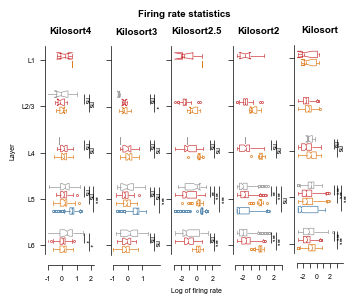

In [6]:
fig = plot_source_data(df_fr)
os.makedirs("figures/8_source_data/supp_fig4b", exist_ok=True)
plt.savefig("figures/8_source_data/supp_fig4b/supp_fig4b.svg", bbox_inches="tight", **savefig_cfg)
with pd.ExcelWriter("figures/8_source_data/supp_fig4b/supp_fig4b.xlsx") as writer:
    df_fr.to_excel(writer, sheet_name="log10_firing_rates", index=False)
    stats.to_excel(writer, sheet_name="statistics", index=False)

## Check: replot from the saved source data

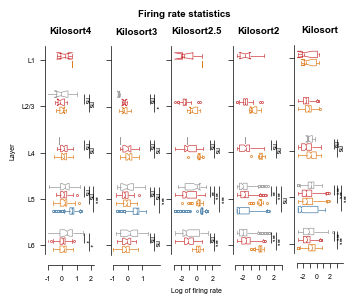

In [7]:
df_fr_loaded = pd.read_excel("figures/8_source_data/supp_fig4b/supp_fig4b.xlsx", sheet_name="log10_firing_rates")
fig = plot_source_data(df_fr_loaded)